# 07. Reaktywność alfy: czy marker działa u tej osoby?

Zadanie **B7** (strumień „B. Dane i dowody”, MUST). Pomysł z `docs/analiza-i-adaptacja.md` §5.5: krótka kalibracja
(oczy otwarte, potem oczy zamknięte) daje (1) osobistą liczbę „reaktywności alfy” i (2) werdykt **„tak / słabo / nie”**:
czy szybki wskaźnik Wachty w ogóle reaguje u tej osoby. Do tego (3): ile sekund z zamkniętymi oczami wystarczy.

**Dlaczego to potrzebne.** Szybki wskaźnik produktu to z-score wyrazistości alfy na O1/O2 względem pierwszych 60 czystych okien.
U części ludzi alfa przy zamkniętych oczach rośnie słabo (na danych publicznych AUC na osobę od 0,52 do 0,91, notebook 04).
U takiej osoby system nie zobaczy spadku czujności z EEG i powinien to powiedzieć wprost, zamiast pokazywać „wszystko w porządku”.

**Co tu sprawdzamy, a czego nie.** Test mierzy, czy marker *reaguje* na zamknięcie oczu (najsilniejszy sygnał alfy, jaki widzi ten sprzęt).
**Nie mierzy senności** i nie mówi nic o tym, czy dana osoba jest zmęczona. To kontrola sprzętu i markera, jak sprawdzenie, czy czujnik
jest dobrze założony i czy u tej osoby ma sens.

**Dane:**
- 5 nagrań zespołu (BrainAccess MINI, suche elektrody): `adi`, `filip`, `rudy`, `wojtek` (południe; blok `neutral` to **swobodna rozmowa**,
  a nie cichy spoczynek) i `wojtek-t1` (wieczór; 60 s cichej fiksacji `eyes_open`, 60 s `eyes_closed`, liczenie, 15 min monotonii, bardzo czysty sygnał);
- COG-BCI (Hinss i in., Zenodo 7413650): spoczynek z oczami otwartymi i zamkniętymi (`RS_Beg_EO`, `RS_Beg_EC`, po 60 s), 29 osób, elektrody żelowe;
  sesja S1 jako populacja odniesienia, sesje S2 i S3 (ok. tydzień później) do sprawdzenia poza próbą.

**Kod produktu tylko czytamy** (`src/wachta/`). Detektor uruchamiamy przez `wachta.pipeline` z niezmienioną konfiguracją.
Inną kalibrację robimy cienką nakładką w notebooku (`PresetBaseline`: ta sama klasa `Baseline`, tylko wypełniona wybranymi oknami).

Notebook działa w Colabie (sam sklonuje repo, jeśli nie znajdzie `src/` i `data/recordings/`). Pobranie COG-BCI: 29 osób × 3 sesje × 2 pliki
po ok. 8 MB, przez zapytania HTTP z zakresem (`remotezip`), surowe pliki są kasowane od razu po przeliczeniu.


In [1]:
%pip install -q mne remotezip

In [2]:
import hashlib
import shutil
import subprocess
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

mne.set_log_level("ERROR")
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 85, "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 200)


def find_repo():
    """Repo root with src/wachta and data/recordings (checkout, or a fresh clone in Colab)."""
    for p in [Path("../.."), Path("."), Path("/content/repo")]:
        if (p / "src" / "wachta" / "pipeline.py").exists() and list((p / "data" / "recordings").glob("*raw.fif")):
            return p
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/wskalecki/Heroes_of_the_brain_AI_All_IN.git", "/content/repo"],
                   capture_output=True)
    p = Path("/content/repo")
    if (p / "src" / "wachta" / "pipeline.py").exists():
        return p
    raise FileNotFoundError("Nie znaleziono repo z src/wachta i data/recordings (sklonuj repo albo uruchom z data/analysis).")


REPO = find_repo()
sys.path.insert(0, str((REPO / "src").resolve()))
from wachta.baseline import Baseline                       # noqa: E402  (product code, read-only)
from wachta.config import CHANNELS, Z_FEATURES, Config     # noqa: E402
from wachta.pipeline import Pipeline, run_offline          # noqa: E402
from wachta.recordings import find_recordings, load_annotations, load_eeg  # noqa: E402

CFG = Config()                       # exactly the product configuration
SKIP_EC = 10                         # seconds skipped at the start of a team eyes-closed block (closing + alpha onset)
N_BOOT = 2000
BOOT_BLOCK = 5                       # moving-block bootstrap: 5 overlapping windows per block
RNG = np.random.default_rng(7)
COLORS = {"adi": "tab:blue", "filip": "tab:orange", "rudy": "tab:green", "wojtek": "tab:red", "wojtek-t1": "tab:purple"}

DATA = Path("/content/data") if Path("/content").exists() else Path.home() / ".cache" / "wachta-eeg"
COG_DIR = DATA / "cogbci-rs-b7"      # small cached 8-channel arrays (about 1 MB per subject)
COG_DIR.mkdir(parents=True, exist_ok=True)
COG_URL = "https://zenodo.org/records/7413650/files/{sub}.zip?download=1"
COG_SUBJECTS = [f"sub-{i:02d}" for i in range(1, 30)]
print("konfiguracja produktu: z_enter =", CFG.z_enter, "| z_exit =", CFG.z_exit, "| cal_windows =", CFG.cal_windows,
      "| smooth =", CFG.smooth_windows, "| lapse_min_s =", CFG.lapse_min_s, "| reject_uv =", CFG.reject_uv)

konfiguracja produktu: z_enter = 2.5 | z_exit = 1.0 | cal_windows = 60 | smooth = 5 | lapse_min_s = 3.0 | reject_uv = 300.0


## 1. Dane i cechy okien

**Nagrania zespołu.** Każde nagranie przechodzi przez `wachta.pipeline.run_offline` z konfiguracją produktu
(filtr przyczynowy 1–40 Hz z notchem 50 Hz, okna 2 s co 1 s, odrzucanie > 300 µV, kalibracja z pierwszych 60 czystych okien).
Z wyniku bierzemy dla każdego okna: wyrazistość alfy `alpha_prom` (log10 mocy 8–12 Hz względem średniej geometrycznej 5–7 i 14–16 Hz, O1/O2),
moc alfy `alpha_occ` (log10 µV², O1/O2), znacznik odrzucenia i stan detektora. Okno należy do bloku, gdy mieści się w nim w całości.

**COG-BCI.** Pliki `RS_Beg_EO` i `RS_Beg_EC` z sesji S1 (po 60 s, oczy otwarte / zamknięte). Obróbka jak w produkcie: nasze 8 kanałów,
referencja Fp1 (odjęcie Fp1), przepróbkowanie do 250 Hz, a potem **ten sam** `Pipeline` (filtr 1–40 Hz, okna, odrzucanie).
Surowe pliki `.set/.fdt` kasujemy od razu po przeliczeniu; w cache zostają tylko małe tablice 8 × 15000 próbek.

In [3]:
def block_of(t_end, blocks, win_s=CFG.win_s):
    for b in blocks:
        if t_end - win_s >= b.onset and t_end <= b.end:
            return b.label
    return "transition"


def to_table(results, blocks=()):
    return pd.DataFrame({
        "t": [r["t"] for r in results],
        "bad": [r["bad"] for r in results],
        "prom": [r["features"]["alpha_prom"] for r in results],
        "apow": [r["features"]["alpha_occ"] for r in results],
        "block": [block_of(r["t"], blocks) for r in results],
    })


REC = REPO / "data" / "recordings"
TEAM = {}
for name, path in find_recordings(REC).items():
    eeg, fs = load_eeg(path)
    assert fs == CFG.sfreq
    blocks = load_annotations(path)
    res = run_offline(eeg, CFG)
    T = to_table(res, blocks)
    ec = next(b for b in blocks if b.label == "eyes_closed")
    cal_idx = T.index[~T.bad][:CFG.cal_windows]                    # what the product calibrates on
    TEAM[name] = dict(eeg=eeg, blocks=blocks, res=res, T=T, ec=ec, cal_idx=cal_idx)

pd.DataFrame({n: {"długość [s]": round(d["T"].t.iloc[-1]), "okna odrzucone [%]": round(100 * d["T"].bad.mean(), 1),
                  "kalibracja produktu [s]": f"{d['T'].t[d['cal_idx'][0]] - 2:.0f}–{d['T'].t[d['cal_idx'][-1]]:.0f}",
                  "blok eyes_closed [s]": f"{d['ec'].onset:.0f}–{d['ec'].end:.0f}",
                  "odniesienie EO": "eyes_open (fiksacja)" if n == "wojtek-t1" else "neutral (rozmowa)"}
              for n, d in TEAM.items()}).T

,długość [s],okna odrzucone [%],kalibracja produktu [s],blok eyes_closed [s],odniesienie EO
adi,548,10.1,4–67,300–360,neutral (rozmowa)
filip,880,3.2,1–62,600–660,neutral (rozmowa)
rudy,543,15.3,1–75,300–360,neutral (rozmowa)
wojtek-t1,1091,0.7,1–62,63–123,eyes_open (fiksacja)
wojtek,509,10.8,1–63,300–363,neutral (rozmowa)


In [4]:
def get_cog(sub, ses="S1"):
    """8 channels, Fp1 reference, 250 Hz, volts: arrays for eyes open and eyes closed (cached)."""
    out = COG_DIR / f"{sub}_{ses}.npz"
    if out.exists():
        d = np.load(out)
        return d["EO"].astype(float), d["EC"].astype(float)
    from remotezip import RemoteZip
    tmp = COG_DIR / f"tmp-{sub}-{ses}"
    with RemoteZip(COG_URL.format(sub=sub)) as z:          # layouts differ (sub-03/sub-03/...): match by suffix
        for n in z.namelist():
            if any(n.endswith(f"ses-{ses}/eeg/RS_Beg_{s}.{e}") for s in ("EC", "EO") for e in ("set", "fdt")):
                z.extract(n, tmp)
    arr = {}
    for s in ("EO", "EC"):
        raw = mne.io.read_raw_eeglab(next(tmp.rglob(f"ses-{ses}/eeg/RS_Beg_{s}.set")), preload=True)
        raw.rename_channels(lambda n: n.replace("EEG ", "").strip())
        raw.set_annotations(None)
        raw.set_eeg_reference(["Fp1"], projection=False)   # our hardware reference
        raw.pick(list(CHANNELS)).reorder_channels(list(CHANNELS))
        raw.resample(CFG.sfreq)
        arr[s] = raw.get_data().astype(np.float32)
    shutil.rmtree(tmp, ignore_errors=True)                 # delete the extracted .set/.fdt
    np.savez(out, **arr)
    return arr["EO"].astype(float), arr["EC"].astype(float)


class PresetBaseline(Baseline):
    """Product Baseline (median + scaled MAD), but filled from chosen windows instead of the first clean ones."""

    def __init__(self, feature_rows):
        super().__init__(Z_FEATURES, len(feature_rows))
        for f in feature_rows:
            self.add(f)


def run_with_baseline(eeg, cfg=CFG, feature_rows=None):
    """Same loop as wachta.pipeline.run_offline; optionally with the baseline preset from `feature_rows`."""
    p = Pipeline(cfg)
    if feature_rows is not None:
        p.baseline = PresetBaseline(feature_rows)
    step = p.cfg.step_samples
    out = []
    for s in range(0, eeg.shape[1], step):
        out.extend(p.push(eeg[:, s:s + step]))
    return out


COG, seen, dupes = {}, {}, []
for sub in COG_SUBJECTS:
    try:
        eo, ec = get_cog(sub)
    except Exception as e:
        print("pomijam", sub, "-", type(e).__name__)
        continue
    h = hashlib.md5(eo.tobytes() + ec.tobytes()).hexdigest()
    if h in seen:                                          # identical recordings under two subject ids
        dupes.append((sub, seen[h]))
        continue
    seen[h] = sub
    r_eo = run_offline(eo, CFG)
    T_eo = to_table(r_eo)
    feo = [r["features"] for r in r_eo if not r["bad"]]
    r_ec = run_with_baseline(ec, CFG, feo)                 # calibration step: baseline = this person's EO minute
    COG[sub] = dict(T_eo=T_eo, T_ec=to_table(r_ec), res_ec=r_ec, res_eo=run_with_baseline(eo, CFG, feo))
print(f"COG-BCI: {len(COG)} unikalnych osób; duplikaty pominięte: {dupes}")
print("okna odrzucone EO [%], mediana (min–max):",
      np.round(np.median([100 * c["T_eo"].bad.mean() for c in COG.values()]), 1),
      f"({min(100 * c['T_eo'].bad.mean() for c in COG.values()):.0f}–{max(100 * c['T_eo'].bad.mean() for c in COG.values()):.0f})")

COG-BCI: 27 unikalnych osób; duplikaty pominięte: [('sub-27', 'sub-17'), ('sub-28', 'sub-25')]
okna odrzucone EO [%], mediana (min–max): 3.5 (0–58)


## 2. Miara reaktywności

Dla każdej osoby mamy okna 2 s w dwóch stanach: **EO** (oczy otwarte, odniesienie) i **EC** (oczy zamknięte).
Porównaliśmy trzy kandydatki na „liczbę reaktywności”:

| Miara | Definicja | Za | Przeciw |
|---|---|---|---|
| **R_z** (główna) | (mediana prom. EC − mediana prom. EO) / MAD prom. EO, MAD przeskalowane ×1,4826 | to dokładnie jednostka, w której pracuje detektor (z-score względem kalibracji, próg `z_enter` = 2,5), więc da się ją wprost porównać z progiem alarmu | zależy od szumu odniesienia EO: głośne EO (rozmowa) daje duże MAD i mniejsze R_z |
| Δprom | mediana prom. EC − mediana prom. EO (log10) | bez jednostek urządzenia, nie zależy od rozrzutu EO | nie mówi, czy skok wystaje ponad szum, a detektor właśnie tego potrzebuje |
| Δlog10 moc alfy | różnica median log10 mocy 8–12 Hz (stosunek mocy EC/EO = 10^Δ) | klasyczny „współczynnik reaktywności” z literatury | moc całego pasma zależy od impedancji i ruchu; przy szerokopasmowych artefaktach (rozmowa) rośnie także przy otwartych oczach |

Wyrazistość alfy jest już logarytmem stosunku, więc różnica wyrazistości to log stosunku „alfa względem sąsiadów” w EC do EO.
Mediany zamiast średnich, bo pojedyncze mrugnięcia i ruchy nie powinny przesuwać wyniku (tak samo robi `Baseline` w produkcie).

**Przedziały ufności:** bootstrap blokowy po oknach (bloki po 5 okien, bo okna nachodzą na siebie w 50% i są skorelowane), osobno w EO i EC,
2000 powtórzeń dla wariantu głównego. Przedział R_z jest szeroki, bo MAD z ~60 okien też jest niepewne; to uczciwa niepewność samego testu.

**Warianty dla nagrań zespołu:** odniesienie EO = okna kalibracji produktu (`cal60`, pierwsze 60 czystych okien) albo minuta tuż przed blokiem
(`last60`); EC od początku bloku albo od 10. sekundy (pierwsze 7–13 s to ruch zamykania oczu i narastanie alfy, a adnotacje mogą być przesunięte
o kilka sekund). Wariant główny: `cal60` i pominięte 10 s, bo właśnie względem `cal60` liczy z-score detektor.


In [5]:
def mad(x):
    x = np.asarray(x, float)
    return 1.4826 * np.median(np.abs(x - np.median(x)))


def reactivity(eo, ec, eo_pow=None, ec_pow=None):
    """Point estimates: R_z (product z units), delta prominence (log10), delta log10 alpha power."""
    out = {"R_z": (np.median(ec) - np.median(eo)) / mad(eo), "d_prom": np.median(ec) - np.median(eo)}
    if eo_pow is not None:
        out["d_logpow"] = np.median(ec_pow) - np.median(eo_pow)
    return out


def mbb(n, rng, block=BOOT_BLOCK):
    """Indices of one moving-block bootstrap sample (windows overlap by 50 %, so resample blocks, not windows)."""
    starts = rng.integers(0, max(n - block, 0) + 1, int(np.ceil(n / block)))
    return np.concatenate([np.arange(s, min(s + block, n)) for s in starts])[:n]


def boot(eo, ec, eo_pow, ec_pow, n_boot=N_BOOT):
    eo, ec, eo_pow, ec_pow = map(np.asarray, (eo, ec, eo_pow, ec_pow))
    rows = []
    for _ in range(n_boot):
        i, j = mbb(len(eo), RNG), mbb(len(ec), RNG)
        rows.append(reactivity(eo[i], ec[j], eo_pow[i], ec_pow[j]))
    return pd.DataFrame(rows)


def ci(s):
    return f"{np.percentile(s, 2.5):.2f}–{np.percentile(s, 97.5):.2f}"


def segments(name, eo_ref="cal60", skip=SKIP_EC):
    d = TEAM[name]
    T, ec = d["T"], d["ec"]
    if eo_ref == "cal60":
        E = T.loc[d["cal_idx"]]
    else:                                   # the 60 s right before the eyes-closed block
        E = T[(T.t - 2 >= ec.onset - 60) & (T.t <= ec.onset) & ~T.bad]
    C = T[(T.t - 2 >= ec.onset + skip) & (T.t <= ec.end) & ~T.bad]
    return E, C


rows, BOOT_TEAM = [], {}
for n in TEAM:
    for ref in ("cal60", "last60"):
        for skip in (0, SKIP_EC):
            E, C = segments(n, ref, skip)
            r = reactivity(E.prom, C.prom, E.apow, C.apow)
            b = boot(E.prom, C.prom, E.apow, C.apow, n_boot=N_BOOT if (ref, skip) == ("cal60", SKIP_EC) else 500)
            if (ref, skip) == ("cal60", SKIP_EC):
                BOOT_TEAM[n] = b
            rows.append({"osoba": n, "odniesienie EO": ref, "pominięte s EC": skip, "okna EO": len(E), "okna EC": len(C),
                         "prom EO (mediana)": np.median(E.prom), "prom EC (mediana)": np.median(C.prom),
                         "MAD prom EO": mad(E.prom), "Δprom": r["d_prom"], "Δprom 95% CI": ci(b.d_prom),
                         "R_z": r["R_z"], "R_z 95% CI": ci(b.R_z),
                         "Δlog10 moc alfy": r["d_logpow"], "Δlog10 moc 95% CI": ci(b.d_logpow),
                         "stosunek mocy EC/EO": 10 ** r["d_logpow"]})
RT = pd.DataFrame(rows)
RT.round(2)

,osoba,odniesienie EO,pominięte s EC,okna EO,okna EC,prom EO (mediana),prom EC (mediana),MAD prom EO,Δprom,Δprom 95% CI,R_z,R_z 95% CI,Δlog10 moc alfy,Δlog10 moc 95% CI,stosunek mocy EC/EO
0,adi,cal60,0,60,59,-0.06,0.31,0.19,0.37,0.28–0.54,1.93,1.45–3.71,0.12,-0.03–0.29,1.31
1,adi,cal60,10,60,49,-0.06,0.34,0.19,0.40,0.31–0.56,2.09,1.59–3.98,0.15,-0.03–0.31,1.40
2,adi,last60,0,54,59,-0.09,0.31,0.19,0.40,0.30–0.54,2.09,1.19–3.21,0.15,0.01–0.36,1.42
3,adi,last60,10,54,49,-0.09,0.34,0.19,0.43,0.32–0.55,2.25,1.31–3.36,0.18,-0.00–0.37,1.52
4,filip,cal60,0,60,59,0.17,0.99,0.19,0.82,0.74–0.96,4.32,2.30–5.01,1.18,1.07–1.32,14.98
5,filip,cal60,10,60,49,0.17,1.00,0.19,0.83,0.72–0.98,4.37,2.29–5.06,1.18,1.07–1.33,15.15
6,filip,last60,0,59,59,0.06,0.99,0.26,0.93,0.86–1.11,3.60,2.94–5.95,1.21,1.12–1.34,16.04
7,filip,last60,10,59,49,0.06,1.00,0.26,0.94,0.85–1.11,3.64,2.91–6.19,1.21,1.14–1.36,16.22
8,rudy,cal60,0,60,59,0.06,0.86,0.30,0.80,0.69–0.91,2.64,1.93–3.87,0.53,0.42–0.69,3.38
9,rudy,cal60,10,60,49,0.06,0.84,0.30,0.78,0.64–0.90,2.56,1.83–3.68,0.53,0.40–0.69,3.35


**Nagrania zespołu: co widać w tabeli**

- **U wszystkich pięciu nagrań wyrazistość alfy rośnie po zamknięciu oczu**, a przedział ufności Δprom nie obejmuje zera
  (wariant główny: od 0,40 u adi do 0,83 u filipa). R_z w wariancie głównym: adi 2,09, filip 4,37, rudy 2,56, wojtek-t1 2,23, wojtek 3,20.
- **Przedziały R_z są szerokie** (np. adi 1,59–3,98, rudy 1,83–3,68). Jedna minuta EO i jedna minuta EC to mało, żeby ocenić osobę
  z dokładnością do ułamka odchylenia. To trzeba pamiętać przy progach.
- **Moc alfy jako miara reaktywności zawodzi przy rozmowie w odniesieniu.** Stosunek mocy EC/EO: filip 15,2, wojtek-t1 7,7, rudy 3,4,
  wojtek 2,0, adi 1,4 (przedział Δlog10 mocy u adi obejmuje zero). U wojtka względem minuty rozmowy tuż przed blokiem moc alfy
  przy zamkniętych oczach jest wręcz *niższa* (stosunek 0,91), a wyrazistość rośnie wyraźnie (Δprom 0,59). Rozmowa podnosi moc
  w całym widmie (mięśnie, ruch), więc „alfa w mocy” rośnie też przy otwartych oczach. Wyrazistość porównuje alfę z sąsiednimi pasmami
  i jest na to odporna. Dlatego moc zostaje tylko miarą pomocniczą.
- **Pominięcie pierwszych 10 s bloku podnosi R_z** (adi 1,93 → 2,09, wojtek 2,70 → 3,20), bo początek bloku zawiera zamykanie oczu
  i narastanie alfy.
- **Wybór odniesienia EO zmienia wynik o kilka dziesiątych do prawie jednego odchylenia:** wojtek 3,20 (kalibracja na początku rozmowy)
  wobec 2,33 (minuta rozmowy tuż przed blokiem), rudy 2,56 wobec 3,25. Rozmowa nie jest stałym stanem odniesienia.
- **Cicha fiksacja (wojtek-t1) nie dała węższej bazy niż rozmowa:** MAD wyrazistości w EO 0,30, a w rozmowie od 0,19 do 0,30.
  Przy spokojnie otwartych oczach alfa też się pojawia i znika, więc rozrzut EO nie maleje.

**Konsekwencja dla kalibracji.** Rozmowa jako odniesienie ma dwie wady: jej poziom wyrazistości zależy od tego, kiedy i jak ktoś mówi
(wojtek: 3,20 kontra 2,33 w zależności od wybranej minuty), a mowa dokłada mięśnie i ruch, które rozmywają kontrast. Cicha fiksacja mierzy
właściwy kontrast (spokojne oczy otwarte kontra zamknięte), czyli dokładnie to, co detektor ma potem rozróżniać przy pracy w ciszy.
Dlatego krok kalibracji w dashboardzie powinien prosić o **spokojne patrzenie w punkt, bez mówienia**. Uwaga: na naszych danych to wniosek
z jednego nagrania z fiksacją (wojtek-t1: zero fałszywych alarmów w 15 min monotonii), a nie zmierzona różnica między dwiema kalibracjami
u tej samej osoby. Węższej bazy fiksacja nie dała (MAD 0,30), więc zysk jest w trafności poziomu odniesienia, nie w mniejszym szumie.


In [6]:
rows = []
for sub, c in COG.items():
    E = c["T_eo"][~c["T_eo"].bad]
    C = c["T_ec"][~c["T_ec"].bad]
    r = reactivity(E.prom, C.prom, E.apow, C.apow)
    b = boot(E.prom, C.prom, E.apow, C.apow, n_boot=500)
    rows.append({"osoba": sub, "okna EO": len(E), "okna EC": len(C), "prom EO": np.median(E.prom), "prom EC": np.median(C.prom),
                 "MAD prom EO": mad(E.prom), "Δprom": r["d_prom"], "R_z": r["R_z"], "R_z 95% CI": ci(b.R_z),
                 "R_z_lo": np.percentile(b.R_z, 2.5), "R_z_hi": np.percentile(b.R_z, 97.5),
                 "Δlog10 moc alfy": r["d_logpow"], "stosunek mocy EC/EO": 10 ** r["d_logpow"]})
RC = pd.DataFrame(rows).set_index("osoba")
print("COG-BCI, rozkład (n = %d):" % len(RC))
print(RC[["Δprom", "R_z", "Δlog10 moc alfy", "stosunek mocy EC/EO", "MAD prom EO"]]
      .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_string())
team_main = RT[(RT["odniesienie EO"] == "cal60") & (RT["pominięte s EC"] == SKIP_EC)].set_index("osoba")
print("\nGdzie są osoby z zespołu w rozkładzie COG-BCI (percentyl R_z / Δprom / Δlog10 moc):")
for n, r in team_main.iterrows():
    pct = lambda col: 100 * np.mean(RC[col] < r[col])
    print(f"  {n:10s} R_z={r.R_z:4.2f} (P{pct('R_z'):.0f})  Δprom={r['Δprom']:.2f} (P{pct('Δprom'):.0f})  "
          f"Δlog10 moc={r['Δlog10 moc alfy']:.2f} (P{pct('Δlog10 moc alfy'):.0f})")
print("\nSpearman między miarami w COG-BCI:")
print(RC[["R_z", "Δprom", "Δlog10 moc alfy", "MAD prom EO"]].corr(method="spearman").round(2).to_string())

COG-BCI, rozkład (n = 27):
       Δprom    R_z  Δlog10 moc alfy  stosunek mocy EC/EO  MAD prom EO
count  27.00  27.00            27.00                27.00        27.00
mean    0.64   2.05             0.63                 6.89         0.34
std     0.33   1.24             0.42                 8.39         0.12
min    -0.01  -0.05            -0.04                 0.92         0.18
10%     0.25   0.76             0.12                 1.32         0.23
25%     0.40   1.06             0.35                 2.24         0.27
50%     0.62   1.81             0.54                 3.49         0.31
75%     0.86   2.78             0.96                 9.15         0.35
90%     1.10   3.69             1.14                13.96         0.51
max     1.24   4.68             1.62                41.96         0.71

Gdzie są osoby z zespołu w rozkładzie COG-BCI (percentyl R_z / Δprom / Δlog10 moc):
  adi        R_z=2.09 (P52)  Δprom=0.40 (P26)  Δlog10 moc=0.15 (P15)
  filip      R_z=4.37 (P96)  Δprom=0.8

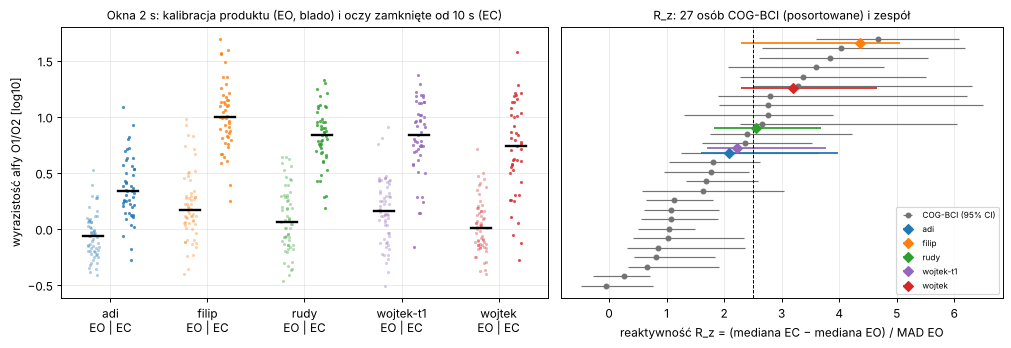

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
for k, n in enumerate(TEAM):
    for ref, off, mk in (("cal60", -0.18, "o"), ("ec", 0.18, "o")):
        E, C = segments(n, "cal60", SKIP_EC)
        v = E.prom if ref == "cal60" else C.prom
        x = k + off + RNG.uniform(-0.06, 0.06, len(v))
        ax.scatter(x, v, s=7, color=COLORS[n], alpha=0.35 if ref == "cal60" else 0.8, lw=0)
        ax.plot([k + off - 0.1, k + off + 0.1], [np.median(v)] * 2, color="k", lw=2)
ax.set_xticks(range(len(TEAM)), [f"{n}\nEO | EC" for n in TEAM])
ax.set_ylabel("wyrazistość alfy O1/O2 [log10]")
ax.set_title("Okna 2 s: kalibracja produktu (EO, blado) i oczy zamknięte od 10 s (EC)", fontsize=10)
ax = axes[1]
order = RC.sort_values("R_z")
ax.errorbar(order.R_z, range(len(order)), xerr=[order.R_z - order.R_z_lo, order.R_z_hi - order.R_z],
            fmt="o", color="0.45", ms=4, lw=1, label="COG-BCI (95% CI)")
for n, r in team_main.iterrows():
    b = BOOT_TEAM[n].R_z
    y = np.interp(r.R_z, order.R_z, range(len(order)))
    ax.errorbar(r.R_z, y, xerr=[[r.R_z - np.percentile(b, 2.5)], [np.percentile(b, 97.5) - r.R_z]],
                fmt="D", color=COLORS[n], ms=6, lw=1.5, label=n)
ax.axvline(CFG.z_enter, color="k", lw=0.8, ls="--")
ax.set_yticks([])
ax.set_xlabel("reaktywność R_z = (mediana EC − mediana EO) / MAD EO")
ax.set_title("R_z: 27 osób COG-BCI (posortowane) i zespół", fontsize=10)
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

**COG-BCI: rozkład w populacji i miejsce zespołu**

- W publicznym zbiorze **dwie pary „osób” mają identyczne pliki** (`sub-27` = `sub-17`, `sub-28` = `sub-25`, te same dane i ta sama suma CRC
  pliku `.fdt` w archiwum). Liczymy więc **27 unikalnych osób**.
- **Reaktywność bardzo się różni między ludźmi:** R_z od −0,05 do 4,68, mediana 1,81 (kwartyle 1,06–2,78, P10 = 0,76, P90 = 3,69).
  Stosunek mocy alfy EC/EO: mediana 3,5, od 0,9 do 42. Kilka osób praktycznie nie reaguje (R_z poniżej 0,3: `sub-24`, `sub-21`).
- **Zespół jest w środku albo w górnej części rozkładu R_z:** adi P52, wojtek-t1 P56, rudy P63, wojtek P78, filip P96.
  Suche elektrody nie zepchnęły nas na dół rozkładu. Na Δprom i na mocy adi wypada niżej (P26 i P15): jego skok alfy jest mały,
  ale też bardzo mały jest rozrzut w kalibracji, więc w jednostkach detektora wychodzi przeciętnie.
- R_z i Δprom są silnie zgodne (Spearman 0,86), z mocą słabiej (0,64). R_z maleje, gdy rośnie rozrzut EO (−0,41): ta sama zmiana alfy
  znaczy mniej przy głośnej kalibracji. To zamierzone, bo tak samo „widzi” ją detektor.


In [8]:
def evaluate(res, blocks, ec, test_from=0.0):
    """Detection of the eyes-closed block by the product state machine (same rules as experiments/validate-on-recordings.py)."""
    cal = [r for r in res if r["calibrated"]]
    lab = [block_of(r["t"], blocks) for r in cal]
    inside = [r for r, l in zip(cal, lab) if l == "eyes_closed" and r["t"] - 2 >= ec.onset + test_from]
    outside = [r for r, l in zip(cal, lab) if l not in ("eyes_closed", "transition")]
    starts = [r["t"] for r in cal if r["new_lapse"]]
    hits = [t for t in starts if ec.onset <= t <= ec.end]
    fa = [t for t in starts if not ec.onset <= t <= ec.end + CFG.win_s]
    return {"wykryte": bool(hits), "opóźnienie [s]": hits[0] - ec.onset if hits else np.nan,
            "pokrycie bloku [%]": 100 * np.mean([r["lapse"] for r in inside]),
            "fałszywe alarmy": len(fa), "minut poza blokiem": len(outside) / 60}


def feats(name, lo, hi):
    """Feature dicts of the clean windows fully inside [lo, hi] s."""
    return [r["features"] for r in TEAM[name]["res"] if not r["bad"] and r["t"] - 2 >= lo and r["t"] <= hi]


rows, PERSONAL_Z = [], {}
for n, d in TEAM.items():
    eeg, B, ec = d["eeg"], d["blocks"], d["ec"]
    eo_rows = feats(n, ec.onset - 60, ec.onset)                   # EO minute right before the eyes-closed block
    ec_rows = feats(n, ec.onset + SKIP_EC, ec.onset + 30)          # first 20 s of eyes closed after the skip
    pe = np.array([f["alpha_prom"] for f in eo_rows]); pc = np.array([f["alpha_prom"] for f in ec_rows])
    jump = (np.median(pc) - np.median(pe)) / mad(pe)
    z_pers = float(np.clip(0.5 * jump, 1.5, CFG.z_enter))
    PERSONAL_Z[n] = (jump, z_pers)
    variants = {
        "a) produkt: 60 pierwszych czystych okien": (CFG, None),
        "b0) baza = minuta EO przed blokiem": (CFG, eo_rows),
        "b1) baza = EO + 20 s EC razem": (CFG, eo_rows + ec_rows),
        "b2) baza EO, próg = 0,5 × skok (1,5–2,5)": (replace(CFG, z_enter=z_pers, z_exit=0.4 * z_pers), eo_rows),
    }
    for v, (cfg, base) in variants.items():
        res = d["res"] if base is None else run_with_baseline(eeg, cfg, base)
        e = evaluate(res, B, ec)
        e["pokrycie 30–60 s [%]"] = evaluate(res, B, ec, test_from=30)["pokrycie bloku [%]"]
        rows.append({"osoba": n, "wariant": v, **e})
DET = pd.DataFrame(rows)
print("skok R_z z kalibracji (EO minuta przed blokiem vs 10–30 s EC) i próg wariantu b2:",
      {n: (round(j, 2), round(z, 2)) for n, (j, z) in PERSONAL_Z.items()})
DET.set_index(["wariant", "osoba"]).round(1)

skok R_z z kalibracji (EO minuta przed blokiem vs 10–30 s EC) i próg wariantu b2: {'adi': (np.float64(1.79), 1.5), 'filip': (np.float64(4.01), 2.0), 'rudy': (np.float64(3.35), 1.67), 'wojtek-t1': (np.float64(1.9), 1.5), 'wojtek': (np.float64(1.64), 1.5)}


,,wykryte,opóźnienie [s],pokrycie bloku [%],fałszywe alarmy,minut poza blokiem,pokrycie 30–60 s [%]
wariant,osoba,,,,,,
a) produkt: 60 pierwszych czystych okien,adi,True,12.0,69.5,0,7.0,96.6
b0) baza = minuta EO przed blokiem,adi,True,12.0,72.9,0,8.0,100.0
b1) baza = EO + 20 s EC razem,adi,True,48.0,18.6,0,8.0,37.9
"b2) baza EO, próg = 0,5 × skok (1,5–2,5)",adi,True,12.0,78.0,1,8.0,100.0
a) produkt: 60 pierwszych czystych okien,filip,True,8.0,89.8,1,12.6,100.0
b0) baza = minuta EO przed blokiem,filip,True,9.0,88.1,0,13.6,100.0
b1) baza = EO + 20 s EC razem,filip,False,NaN,0.0,0,13.6,0.0
"b2) baza EO, próg = 0,5 × skok (1,5–2,5)",filip,True,8.0,89.8,2,13.6,100.0
a) produkt: 60 pierwszych czystych okien,rudy,True,7.0,91.5,0,5.8,100.0


In [9]:
summ = DET.groupby("wariant", sort=False).agg(wykryte=("wykryte", "sum"), opóźnienie_mediana=("opóźnienie [s]", "median"),
                                             pokrycie_średnio=("pokrycie bloku [%]", "mean"),
                                             pokrycie_30_60_średnio=("pokrycie 30–60 s [%]", "mean"),
                                             fałszywe_alarmy=("fałszywe alarmy", "sum"), minut_poza=("minut poza blokiem", "sum"))
summ["wykryte"] = summ["wykryte"].astype(int).astype(str) + "/5"
summ.round(1)

,wykryte,opóźnienie_mediana,pokrycie_średnio,pokrycie_30_60_średnio,fałszywe_alarmy,minut_poza
wariant,,,,,,
a) produkt: 60 pierwszych czystych okien,5/5,9.0,79.2,93.1,1,47.6
b0) baza = minuta EO przed blokiem,5/5,12.0,67.6,93.8,0,52.8
b1) baza = EO + 20 s EC razem,3/5,48.0,13.7,27.6,0,52.8
"b2) baza EO, próg = 0,5 × skok (1,5–2,5)",5/5,9.0,83.3,97.9,20,52.8


**Detektor produktu przy różnych kalibracjach (nagrania zespołu)**

Warianty:
- **a) produkt:** baza z pierwszych 60 czystych okien nagrania, próg 2,5 (dokładnie `run_offline`);
- **b0) baza = minuta EO tuż przed blokiem** (to, co dałby krok kalibracji „oczy otwarte”, gdyby stał tuż przed testem);
- **b1) baza = EO + 20 s EC razem** (dosłowne „kalibracja z oczami otwartymi i zamkniętymi”);
- **b2) baza EO, ale próg osobisty = połowa skoku R_z z kalibracji**, ograniczony do 1,5–2,5 (pomysł z §5.5: „próg jako ułamek skoku”).
  Skok liczony z 10.–30. s bloku, dlatego pokrycie mierzymy też osobno na 30.–60. s, których kalibracja nie widziała.

Wynik (tabele wyżej):
- **a) produkt:** 5/5 wykrytych, mediana opóźnienia 9 s, średnie pokrycie bloku 79%, 1 fałszywy alarm w 48 min.
- **b0)** też 5/5 i 0 fałszywych alarmów, ale u wojtek-t1 i wojtka alarm przychodzi dopiero po 41 i 32 s. Przy wojtek-t1 baza b0 różni się
  od bazy produktu tylko kilkoma oknami (mediana 0,17 zamiast 0,16), a opóźnienie skacze z 9 do 41 s. **Przy R_z około 2,2 detekcja wisi na włosku:**
  zamknięte oczy dają wartości tuż przy progu, więc drobna zmiana bazy przestawia wynik.
- **b1) wrzucenie okien z zamkniętymi oczami do bazy psuje detekcję:** 3/5 wykrytych, mediana opóźnienia 48 s, pokrycie 14%.
  Środek i rozrzut bazy przesuwają się w stronę „zamkniętych oczu”, więc ich ponowne zamknięcie przestaje wystawać ponad bazę.
- **b2) próg osobisty** podnosi pokrycie (83% całego bloku, 98% na 30.–60. s), ale kosztem **20 fałszywych alarmów zamiast 1**, z czego 14
  w 15 minutach monotonii wojtek-t1 bez żadnego zamknięcia oczu. U ludzi ze słabym skokiem próg spada do 1,5 i łapie zwykłe wahania alfy.

**Wniosek dla kroku kalibracji:** okna z zamkniętymi oczami służą **tylko do werdyktu**. Nie wolno ich dokładać do bazy (b1) ani obniżać
nimi progu (b2). Bazą zostaje spokojna minuta z otwartymi oczami, a próg `z_enter` = 2,5 bez zmian.


In [10]:
rows = []
for sub, c in COG.items():
    ec_block = type(TEAM["adi"]["ec"])(0.0, 60.0, "eyes_closed")
    e = evaluate(c["res_ec"], [ec_block], ec_block)
    fa_eo = sum(r["new_lapse"] for r in c["res_eo"])
    rows.append({"osoba": sub, "R_z": RC.loc[sub, "R_z"], "Δprom": RC.loc[sub, "Δprom"], **e, "alarmy w EO (w próbie)": fa_eo})
DC = pd.DataFrame(rows).set_index("osoba").drop(columns=["fałszywe alarmy", "minut poza blokiem"])
team_cov = DET[DET.wariant.str.startswith("a)")].set_index("osoba")
REL = team_main[["R_z", "Δprom"]].join(team_cov[["wykryte", "opóźnienie [s]", "pokrycie bloku [%]"]])
rho_c = spearmanr(DC.R_z, DC["pokrycie bloku [%]"])
rho_cp = spearmanr(DC["Δprom"], DC["pokrycie bloku [%]"])
rho_cpow = spearmanr(RC["Δlog10 moc alfy"], DC["pokrycie bloku [%]"])
rho_t = spearmanr(REL.R_z, REL["pokrycie bloku [%]"])
print(f"COG-BCI (n={len(DC)}): wykryte {DC.wykryte.sum()}/{len(DC)}; Spearman pokrycia z R_z = {rho_c.statistic:.2f} "
      f"(p={rho_c.pvalue:.1g}), z Δprom = {rho_cp.statistic:.2f}, z Δlog10 mocy = {rho_cpow.statistic:.2f}")
print(f"Zespół (n=5): Spearman pokrycia z R_z = {rho_t.statistic:.2f} (p={rho_t.pvalue:.2f})")
print("alarmy w samej minucie EO (ta sama minuta co kalibracja):", int(DC["alarmy w EO (w próbie)"].sum()))
print()
print(REL.round(2).to_string())
print()
print(DC.sort_values("R_z").round(2).to_string())

COG-BCI (n=27): wykryte 16/27; Spearman pokrycia z R_z = 0.91 (p=5e-11), z Δprom = 0.80, z Δlog10 mocy = 0.64
Zespół (n=5): Spearman pokrycia z R_z = 0.70 (p=0.19)
alarmy w samej minucie EO (ta sama minuta co kalibracja): 0

            R_z  Δprom  wykryte  opóźnienie [s]  pokrycie bloku [%]
osoba                                                              
adi        2.09   0.40     True            12.0               69.49
filip      4.37   0.83     True             8.0               89.83
rudy       2.56   0.78     True             7.0               91.53
wojtek-t1  2.23   0.68     True             9.0               71.19
wojtek     3.20   0.73     True            13.0               74.19

         R_z  Δprom  wykryte  opóźnienie [s]  pokrycie bloku [%]  alarmy w EO (w próbie)
osoba                                                                                   
sub-24 -0.05  -0.01    False             NaN                0.00                       0
sub-21  0.26   0.07    False   

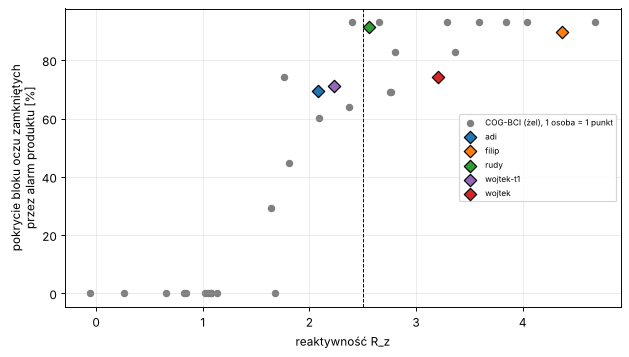

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.scatter(DC.R_z, DC["pokrycie bloku [%]"], color="0.5", s=28, label="COG-BCI (żel), 1 osoba = 1 punkt")
for n, r in REL.iterrows():
    ax.scatter(r.R_z, r["pokrycie bloku [%]"], color=COLORS[n], marker="D", s=55, edgecolor="k", zorder=3, label=n)
ax.axvline(CFG.z_enter, color="k", lw=0.8, ls="--")
ax.set_xlabel("reaktywność R_z")
ax.set_ylabel("pokrycie bloku oczu zamkniętych\nprzez alarm produktu [%]")
ax.legend(fontsize=7, loc="center right")
plt.tight_layout()
plt.show()

**Reaktywność a czułość detektora**

- **COG-BCI (27 osób):** detektor produktu (baza z minuty EO tej osoby, próg 2,5) wykrywa zamknięcie oczu u 16 z 27 osób.
  Pokrycie minuty EC rośnie z R_z bardzo wyraźnie (Spearman 0,91), słabiej z Δprom (0,80) i z mocą (0,64).
  **Uwaga, to w dużej części z definicji:** R_z i pokrycie liczymy z tej samej minuty EC, a R_z to po prostu mediana z-score'u tej minuty.
  Prawdziwe sprawdzenie poza próbą jest niżej (sesje S2 i S3).
- **Zespół (5 nagrań):** wszystkie zamknięcia oczu wykryte, pokrycie od 69% do 92%. Dwa najniższe pokrycia mają osoby z najniższym R_z
  (adi 69% przy 2,09, wojtek-t1 71% przy 2,23), ale wojtek przy R_z 3,20 ma tylko 74% (krótkie otwarcie oczu w środku bloku, opisane
  w `docs/trafnosc-na-nagraniach.md`). Spearman 0,70 przy n = 5 nic nie dowodzi (p = 0,19).
- Na wykresie zespół siedzi tam, gdzie w COG-BCI detekcja już działa (R_z > 2). Osób, u których marker „nie działa”, w zespole nie mamy.
- W samej minucie EO (tej, z której jest baza) detektor nie zgłosił w COG-BCI ani jednego alarmu; to nie jest ocena fałszywych alarmów,
  bo baza i test to te same dane.


In [12]:
T_NO, T_YES = 1.5, 2.5            # proposed verdict thresholds on R_z (see the markdown above)


def verdict(rz):
    return "tak" if rz >= T_YES else ("nie" if rz < T_NO else "słabo")


DC["werdykt"] = DC.R_z.map(verdict)
tab = DC.groupby("werdykt").agg(osób=("R_z", "size"), wykryte=("wykryte", "sum"),
                                pokrycie_min=("pokrycie bloku [%]", "min"), pokrycie_mediana=("pokrycie bloku [%]", "median"),
                                pokrycie_max=("pokrycie bloku [%]", "max"), opóźnienie_mediana=("opóźnienie [s]", "median"))
print("COG-BCI według werdyktu:")
print(tab.reindex(["tak", "słabo", "nie"]).round(1).to_string())

# Where the detector collapses: smallest R_z with a detection, largest R_z without one
print("\nnajmniejsze R_z z wykryciem:", round(DC[DC.wykryte].R_z.min(), 2),
      "| największe R_z bez wykrycia:", round(DC[~DC.wykryte].R_z.max(), 2),
      "| najmniejsze R_z z pokryciem ≥ 60%:", round(DC[DC["pokrycie bloku [%]"] >= 60].R_z.min(), 2))
print("percentyle R_z w COG-BCI dla progów 1,5 i 2,5:",
      round(100 * np.mean(RC.R_z < T_NO)), "i", round(100 * np.mean(RC.R_z < T_YES)))
# the same split on delta prominence, for a device-independent version
for lo, hi in ((0.4, 0.8), (0.45, 0.75)):
    v = np.where(DC["Δprom"] >= hi, "tak", np.where(DC["Δprom"] < lo, "nie", "słabo"))
    print(f"zgodność werdyktu R_z z werdyktem Δprom (progi {lo}/{hi}): {np.mean(v == DC.werdykt) * 100:.0f}%")

rows = []
for n, r in REL.iterrows():
    b = BOOT_TEAM[n].R_z.map(verdict).value_counts(normalize=True)
    alt = RT[(RT.osoba == n) & (RT["odniesienie EO"] == "last60") & (RT["pominięte s EC"] == SKIP_EC)].R_z.iloc[0]
    rows.append({"osoba": n, "R_z": r.R_z, "werdykt": verdict(r.R_z),
                 "pewność (bootstrap)": f"{100 * b.get(verdict(r.R_z), 0):.0f}%",
                 "R_z wobec minuty przed blokiem": alt, "werdykt (minuta przed blokiem)": verdict(alt),
                 "wykryte": r.wykryte, "opóźnienie [s]": r["opóźnienie [s]"], "pokrycie [%]": r["pokrycie bloku [%]"]})
VT = pd.DataFrame(rows).set_index("osoba")
VT.round(2)

COG-BCI według werdyktu:
         osób  wykryte  pokrycie_min  pokrycie_mediana  pokrycie_max  opóźnienie_mediana
werdykt                                                                                 
tak        10       10          69.0              93.1          93.1                 7.0
słabo       7        6           0.0              60.3          93.1                18.0
nie        10        0           0.0               0.0           0.0                 NaN

najmniejsze R_z z wykryciem: 1.64 | największe R_z bez wykrycia: 1.68 | najmniejsze R_z z pokryciem ≥ 60%: 1.76
percentyle R_z w COG-BCI dla progów 1,5 i 2,5: 37 i 63
zgodność werdyktu R_z z werdyktem Δprom (progi 0.4/0.8): 63%
zgodność werdyktu R_z z werdyktem Δprom (progi 0.45/0.75): 67%


,R_z,werdykt,pewność (bootstrap),R_z wobec minuty przed blokiem,werdykt (minuta przed blokiem),wykryte,opóźnienie [s],pokrycie [%]
osoba,,,,,,,,
adi,2.09,słabo,58%,2.25,słabo,True,12.0,69.49
filip,4.37,tak,93%,3.64,tak,True,8.0,89.83
rudy,2.56,tak,54%,3.25,tak,True,7.0,91.53
wojtek-t1,2.23,słabo,60%,2.21,słabo,True,9.0,71.19
wojtek,3.20,tak,92%,2.33,słabo,True,13.0,74.19


## 4. Progi werdyktu „tak / słabo / nie”

Propozycja, w jednostkach R_z (z-score wyrazistości alfy względem kalibracji):

| Werdykt | R_z | Znaczenie | Uzasadnienie z danych |
|---|---|---|---|
| **tak** | ≥ 2,5 | mediana okien z zamkniętymi oczami leży nad progiem alarmu | = `z_enter`; COG-BCI: 10 z 10 osób wykrytych, pokrycie od 69%, mediana opóźnienia 7 s |
| **słabo** | 1,5–2,5 | zamknięcie oczu zwykle wykryte, ale późno albo z przerwami | COG-BCI: 6 z 7 wykrytych, mediana pokrycia 60%, mediana opóźnienia 18 s |
| **nie** | < 1,5 | detektor nie zobaczy nawet zamkniętych oczu | COG-BCI: 0 z 10 wykrytych; granica załamania leży między 1,64 a 1,76 |

- Dolny próg 1,5 to też próg próby reakcji w produkcie (`probe_z`), czyli 0,6 × `z_enter`. Jeśli progi alarmu się zmienią, werdykt warto
  zapisać względnie: „tak” od 1,0 × `z_enter`, „nie” poniżej 0,6 × `z_enter`.
- W COG-BCI te progi dzielą ludzi mniej więcej na trzy części: 37% „nie”, 26% „słabo”, 37% „tak”.
- **Werdykt na Δprom nie jest zamiennikiem:** przy najlepszych sprawdzonych progach zgadza się z werdyktem R_z tylko w 63–67% przypadków.

**Werdykty zespołu** (tabela wyżej): filip „tak” (pewność z bootstrapu 93%), wojtek „tak” (92%), rudy „tak” (tylko 54%, R_z 2,56 tuż nad progiem),
adi „słabo” (58%), wojtek-t1 „słabo” (60%). Zgodność z czułością: wszystkie pięć zamknięć oczu wykryte, a dwa werdykty „słabo” mają najniższe
pokrycie (69% i 71%), ale „tak” u wojtka daje niewiele więcej (74%). Przy innym odniesieniu (minuta tuż przed blokiem) wojtek dostaje „słabo”.
**Trzy z pięciu naszych nagrań leżą blisko progu 2,5, więc ich werdykt jest prawie rzutem monetą.** Nikt z zespołu nie dostał „nie”.

**Niepewność progów:** COG-BCI to 27 osób z elektrodami żelowymi w laboratorium. Nasze 5 nagrań to 4 osoby z suchymi elektrodami.
Progi są wstępne. Ich sens: „tak” = mediana nad progiem alarmu, „nie” = poniżej progu próby. Same wartości trzeba sprawdzić na naszych
pomiarach (punkty T0–T2).


In [13]:
# Out-of-sample check: does the verdict from session S1 predict detection in sessions S2 and S3 (about a week apart)?
rows = []
for ses in ("S2", "S3"):
    seen_s = {}
    for sub in COG:
        try:
            eo, ec = get_cog(sub, ses)
        except Exception as e:
            print("pomijam", sub, ses, "-", type(e).__name__)
            continue
        h = hashlib.md5(eo.tobytes() + ec.tobytes()).hexdigest()
        if h in seen_s:
            print("duplikat:", sub, ses, "=", seen_s[h])
            continue
        seen_s[h] = sub
        r_eo = run_offline(eo, CFG)
        feo = [r["features"] for r in r_eo if not r["bad"]]
        r_ec = run_with_baseline(ec, CFG, feo)
        T_eo, T_ec = to_table(r_eo), to_table(r_ec)
        blk = type(TEAM["adi"]["ec"])(0.0, 60.0, "eyes_closed")
        e = evaluate(r_ec, [blk], blk)
        rz = reactivity(T_eo[~T_eo.bad].prom, T_ec[~T_ec.bad].prom)["R_z"]
        rows.append({"osoba": sub, "sesja": ses, "R_z": rz, "wykryte": e["wykryte"], "pokrycie [%]": e["pokrycie bloku [%]"]})
RS = pd.DataFrame(rows)
RS["R_z S1"] = RS.osoba.map(RC.R_z)
RS["werdykt S1"] = RS["R_z S1"].map(verdict)
RS["werdykt"] = RS.R_z.map(verdict)
for ses, g in RS.groupby("sesja"):
    rho = spearmanr(g["R_z S1"], g.R_z)
    print(f"{ses}: n={len(g)}, Spearman R_z(S1) z R_z({ses}) = {rho.statistic:.2f}, "
          f"ten sam werdykt co w S1: {100 * np.mean(g.werdykt == g['werdykt S1']):.0f}%, "
          f"Spearman R_z(S1) z pokryciem w {ses} = {spearmanr(g['R_z S1'], g['pokrycie [%]']).statistic:.2f}")
print()
RET = RS.groupby("werdykt S1").agg(sesji=("R_z", "size"), wykryte=("wykryte", "sum"),
                                   pokrycie_mediana=("pokrycie [%]", "median"), R_z_mediana=("R_z", "median"))
RET["wykryte [%]"] = 100 * RET.wykryte / RET.sesji
print("Werdykt z S1 a wykrycie zamkniętych oczu w S2 i S3 (kalibracja w każdej sesji od nowa):")
print(RET.reindex(["tak", "słabo", "nie"]).round(1).to_string())
print()
print(pd.crosstab(RS["werdykt S1"], RS.werdykt).reindex(index=["tak", "słabo", "nie"], columns=["tak", "słabo", "nie"]).to_string())

S2: n=27, Spearman R_z(S1) z R_z(S2) = 0.74, ten sam werdykt co w S1: 56%, Spearman R_z(S1) z pokryciem w S2 = 0.73
S3: n=27, Spearman R_z(S1) z R_z(S3) = 0.62, ten sam werdykt co w S1: 44%, Spearman R_z(S1) z pokryciem w S3 = 0.51

Werdykt z S1 a wykrycie zamkniętych oczu w S2 i S3 (kalibracja w każdej sesji od nowa):
            sesji  wykryte  pokrycie_mediana  R_z_mediana  wykryte [%]
werdykt S1                                                            
tak            20       18              92.2          3.4         90.0
słabo          14       10              28.4          1.8         71.4
nie            20        9               0.0          1.6         45.0

werdykt     tak  słabo  nie
werdykt S1                 
tak          15      4    1
słabo         5      3    6
nie           4      7    9


**Sprawdzenie poza próbą: sesje S2 i S3 (ok. tydzień później).** To uczciwszy test niż ten sam blok: werdykt z S1, a wykrycie w innym dniu,
z nowo założonym czepkiem i nową kalibracją.

- **Werdykt z S1 coś przewiduje:** po „tak” zamknięcie oczu w kolejnych sesjach wykryto w 18 z 20 sesji (90%), po „słabo” w 10 z 14 (71%),
  po „nie” w 9 z 20 (45%).
- **Ale werdykt nie jest cechą osoby.** Ten sam werdykt co w S1 ma tylko 56% osób w S2 i 44% w S3. Ranking R_z między sesjami jest umiarkowanie
  stały (Spearman 0,74 i 0,62). Po „nie” w S1 aż 4 sesje dały „tak”. Tych danych nie da się rozdzielić na wpływ stanu osoby
  w danym dniu i wpływ założenia czepka oraz kontaktu elektrod.
- **Konsekwencja:** werdykt liczyć **przy każdej kalibracji** (każdym założeniu czepka) i pokazywać go jako stan *tej sesji*, a nie etykietę
  człowieka. „Nie” znaczy „dziś, przy tym założeniu, EEG nie zobaczy spadku czujności”, a nie „u ciebie to nigdy nie działa”.
  Rozsądna reakcja na „nie”: poprawić założenie i powtórzyć test, a gdy dalej „nie”, oprzeć się na próbach reakcji i kontekście.


In [14]:
EC_LENS = [5, 10, 15, 20, 30, 45, 60]
EO_LENS = [10, 20, 30, 60]


def sel(T, lo, hi):
    return T[(T.t - 2 >= lo) & (T.t <= hi) & ~T.bad]


def trunc_rows(unit, T_eo, eo_t0, E_full, T_ec, ec_t0, ec_len_avail, full_rz, skips):
    """R_z from the first `l_eo` s of the EO reference (60 = the full reference `E_full`)
    and `l_ec` s of EC (all start positions every 5 s after the skip)."""
    out = []
    for l_eo in EO_LENS:
        E = E_full if l_eo == EO_LENS[-1] else sel(T_eo, eo_t0, eo_t0 + l_eo)
        if len(E) < 5 or mad(E.prom) == 0:
            continue
        for skip in skips:
            for l_ec in EC_LENS:
                l_ec_eff = min(l_ec, ec_len_avail - skip)
                if l_ec_eff < l_ec and l_ec != EC_LENS[-1]:
                    continue                                  # "60" means "the whole block after the skip"
                for start in np.arange(skip, ec_len_avail - l_ec_eff + 1e-9, 5.0):
                    C = sel(T_ec, ec_t0 + start, ec_t0 + start + l_ec_eff)
                    if len(C) < 2:
                        continue
                    rz = (np.median(C.prom) - np.median(E.prom)) / mad(E.prom)
                    out.append({"unit": unit, "EO [s]": l_eo, "pominięte [s]": skip, "EC [s]": l_ec, "start": start,
                                "R_z": rz, "błąd": rz - full_rz, "zgodny werdykt": verdict(rz) == verdict(full_rz)})
    return out


rows = []
for n, d in TEAM.items():
    T, ec = d["T"], d["ec"]
    t0 = T.t[d["cal_idx"][0]] - 2                       # start of the product calibration span
    rows += trunc_rows(n, T, t0, T.loc[d["cal_idx"]], T, ec.onset, ec.duration, team_main.loc[n, "R_z"], skips=(0, 5, SKIP_EC))
TR_T = pd.DataFrame(rows)
rows = []
for sub, c in COG.items():
    rows += trunc_rows(sub, c["T_eo"], 0.0, c["T_eo"][~c["T_eo"].bad], c["T_ec"], 0.0, 60.0, RC.loc[sub, "R_z"], skips=(0, 5, SKIP_EC))
TR_C = pd.DataFrame(rows)


def stability(TR, l_eo=60):
    s = TR[TR["EO [s]"] == l_eo]
    g = s.groupby(["pominięte [s]", "EC [s]"])
    return pd.DataFrame({"zgodny werdykt [%]": 100 * g["zgodny werdykt"].mean(),
                         "|błąd R_z| mediana": g["błąd"].apply(lambda x: np.median(np.abs(x))),
                         "|błąd R_z| P90": g["błąd"].apply(lambda x: np.percentile(np.abs(x), 90)),
                         "błąd R_z mediana (znak)": g["błąd"].median()}).unstack(0).round(2)


print("COG-BCI, EO = 60 s, długość EC (wiersze) × pominięte sekundy (kolumny):")
print(stability(TR_C).to_string())
print("\nZespół (5 nagrań, wszystkie położenia okna co 5 s), EO = 60 s:")
print(stability(TR_T).to_string())

COG-BCI, EO = 60 s, długość EC (wiersze) × pominięte sekundy (kolumny):
              zgodny werdykt [%]                 |błąd R_z| mediana             |błąd R_z| P90             błąd R_z mediana (znak)            
pominięte [s]                 0       5       10                 0     5     10             0     5     10                      0     5     10
EC [s]                                                                                                                                        
5                          78.33   78.45   79.26               0.40  0.38  0.38           1.05  1.02  1.01                   -0.00 -0.02 -0.02
10                         84.51   84.44   85.60               0.25  0.23  0.23           0.68  0.67  0.68                    0.01  0.00 -0.00
15                         87.78   87.24   88.43               0.22  0.22  0.22           0.59  0.59  0.59                    0.01 -0.01 -0.01
20                         90.12   90.74   92.59               0.15  0

In [15]:
def eo_effect(TR, skip, l_ec):
    s = TR[(TR["pominięte [s]"] == skip) & (TR["EC [s]"] == l_ec)]
    g = s.groupby("EO [s]")
    return pd.DataFrame({"zgodny werdykt [%]": 100 * g["zgodny werdykt"].mean(),
                         "|błąd R_z| mediana": g["błąd"].apply(lambda x: np.median(np.abs(x)))}).round(2)


print("Wpływ długości EO przy EC = 30 s: COG-BCI (pominięte 5 s)")
print(eo_effect(TR_C, 5, 30).to_string())
print("\nZespół (pominięte 10 s)")
print(eo_effect(TR_T, SKIP_EC, 30).to_string())
print("\nZespół: zgodność werdyktu per nagranie, EO 60 s, pominięte 10 s:")
print((100 * TR_T[(TR_T["EO [s]"] == 60) & (TR_T["pominięte [s]"] == SKIP_EC)]
       .groupby(["unit", "EC [s]"])["zgodny werdykt"].mean()).unstack().round(0).to_string())

Wpływ długości EO przy EC = 30 s: COG-BCI (pominięte 5 s)
        zgodny werdykt [%]  |błąd R_z| mediana
EO [s]                                        
10                   44.70                0.83
20                   70.99                0.45
30                   77.78                0.44
60                   93.83                0.11

Zespół (pominięte 10 s)
        zgodny werdykt [%]  |błąd R_z| mediana
EO [s]                                        
10                    80.0                0.33
20                    52.0                0.72
30                    92.0                0.37
60                    84.0                0.13

Zespół: zgodność werdyktu per nagranie, EO 60 s, pominięte 10 s:
EC [s]        5      10     15     20     30     45     60
unit                                                      
adi         10.0   56.0   75.0   71.0   80.0  100.0  100.0
filip      100.0  100.0  100.0  100.0  100.0  100.0  100.0
rudy        60.0   44.0   62.0   71.0   80.0   50.0

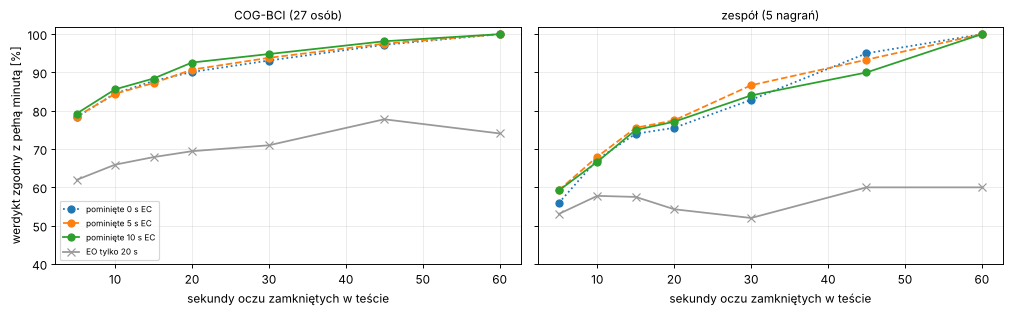

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, TR, title in ((axes[0], TR_C, "COG-BCI (27 osób)"), (axes[1], TR_T, "zespół (5 nagrań)")):
    for skip, ls in ((0, ":"), (5, "--"), (SKIP_EC, "-")):
        s = TR[(TR["EO [s]"] == 60) & (TR["pominięte [s]"] == skip)]
        g = 100 * s.groupby("EC [s]")["zgodny werdykt"].mean()
        ax.plot(g.index, g.values, ls, marker="o", label=f"pominięte {skip} s EC")
    s = TR[(TR["EO [s]"] == 20) & (TR["pominięte [s]"] == (5 if TR is TR_C else SKIP_EC))]
    g = 100 * s.groupby("EC [s]")["zgodny werdykt"].mean()
    ax.plot(g.index, g.values, "-", color="0.6", marker="x", label="EO tylko 20 s")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("sekundy oczu zamkniętych w teście")
    ax.set_ylim(40, 102)
axes[0].set_ylabel("werdykt zgodny z pełną minutą [%]")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## 5. Ile sekund wystarczy

Liczymy R_z z krótszego kawałka i porównujemy werdykt z werdyktem z pełnej minuty (COG-BCI: pełne 60 s EO i 60 s EC;
zespół: kalibracja produktu i blok od 10. s). Dla każdej długości bierzemy **wszystkie położenia** kawałka co 5 s wewnątrz bloku,
więc „zgodny werdykt” to odsetek kawałków, które dają ten sam werdykt co całość.

**Oczy zamknięte (EO = 60 s):**
- COG-BCI: 5 s → 78–79% zgodnych werdyktów, 10 s → 85%, 15 s → 87–88%, **20 s → 90–93%**, **30 s → 93–95%**, 45 s → 97–98%.
  Mediana błędu R_z przy 30 s to 0,11 (90% kawałków mieści się w ±0,35).
- Pominięcie początku w COG-BCI prawie nic nie zmienia, bo nagranie EC zaczyna się, gdy oczy są już zamknięte.
  W naszym protokole pierwsze sekundy to ruch i narastanie alfy, więc **pomijamy 10 s** (sekcja 2: początek bloku zaniża R_z).
- Zespół: 30 s → 83–87%, 45 s → 90–95%. Niezgodności siedzą prawie wyłącznie w trzech nagraniach z R_z blisko 2,5 (adi, rudy, wojtek-t1).
  U filipa (R_z 4,37) werdykt jest ten sam już po 5 s. **Długość testu nie naprawi werdyktu osoby, która leży na granicy.**

**Oczy otwarte (EC = 30 s):**
- COG-BCI: EO 10 s → 45% zgodnych, 20 s → 71%, 30 s → 78%, **60 s → 94%**. Krótkie odniesienie EO jest słabym ogniwem, bo z kilkunastu okien
  nie da się dobrze oszacować rozrzutu (MAD), a R_z dzieli właśnie przez rozrzut.
- Zespół daje tu wyniki niemonotoniczne (80%, 52%, 92%, 84%) i przy 5 nagraniach nie wnioskujemy z nich.

**Zalecenie dla dashboardu:** EO **60 s** (to i tak istniejąca kalibracja, `cal_windows` = 60, więc nie kosztuje dodatkowego czasu),
potem EC **40 s: pierwsze 10 s pomijamy, liczymy z 30 s**. Razem z komunikatami ok. 1 min 45 s. Absolutne minimum: EC 20 s po pominięciu 10 s
(90% zgodności w COG-BCI). Propozycja z §5.5 (30 s EO + 15 s EC) jest za krótka: samo skrócenie EO do 30 s obniża zgodność do 78%.
Gdy R_z wypada blisko progu (±0,35, czyli 90% błędu przy 30 s), dashboard może zaproponować powtórzenie zamknięcia oczu.


## 6. Parametry do `config.py` (issue #18)

Propozycje. Pola nie istnieją jeszcze w `src/wachta/config.py`; nazwy są robocze. „Założenie” = nie wynika bezpośrednio z naszych danych.

| Parametr (roboczo) | Wartość | Skąd | Pewność |
|---|---|---|---|
| `react_eo_windows` | 60 (= `cal_windows`) | COG-BCI: EO 60 s → 94% zgodnych werdyktów, 30 s → 78% | średnia |
| `react_eo_instruction` | „patrz w punkt, nie mów” | rozmowa jako odniesienie zmienia R_z o prawie 1 (wojtek); fiksacja tylko w 1 nagraniu | **założenie** |
| `react_ec_skip_s` | 10 | początek bloku zaniża R_z (adi 1,93 → 2,09, wojtek 2,70 → 3,20); opóźnienie alfy 7–13 s | średnia |
| `react_ec_s` | 30 (minimum 20) | COG-BCI: 30 s → 93–95%, 20 s → 90–93% zgodnych werdyktów | średnia |
| `react_metric` | R_z = (mediana `alpha_prom` EC − mediana EO) / (1,4826 · MAD EO) | Spearman z pokryciem 0,91 (Δprom 0,80, moc 0,64); ta sama jednostka co detektor | średnia |
| `react_yes_z` | 2,5 (= 1,0 × `z_enter`) | COG-BCI: 10/10 wykrytych; tydzień później 90% sesji wykrytych | średnia/niska (żel, n = 27) |
| `react_no_z` | 1,5 (= 0,6 × `z_enter`, = `probe_z`) | COG-BCI: 0/10 wykrytych; tydzień później 45% sesji wykrytych | niska |
| `react_retry_band_z` | ±0,35 wokół progów | P90 błędu R_z przy 30 s EC (COG-BCI) | **założenie** (reguła UX) |
| kiedy liczyć werdykt | przy każdej kalibracji | ten sam werdykt w kolejnej sesji tylko u 44–56% osób | średnia |
| okna EC w bazie | **nie** | wariant b1: 3/5 wykrytych zamiast 5/5 | wysoka |
| `z_enter` osobisty z „ułamka skoku” | **nie**, zostaje 2,5 | wariant b2: 20 fałszywych alarmów zamiast 1 | średnia (n = 5) |


zapisano docs/img/reaktywnosc-alfy-test-markera.png (159 kB)


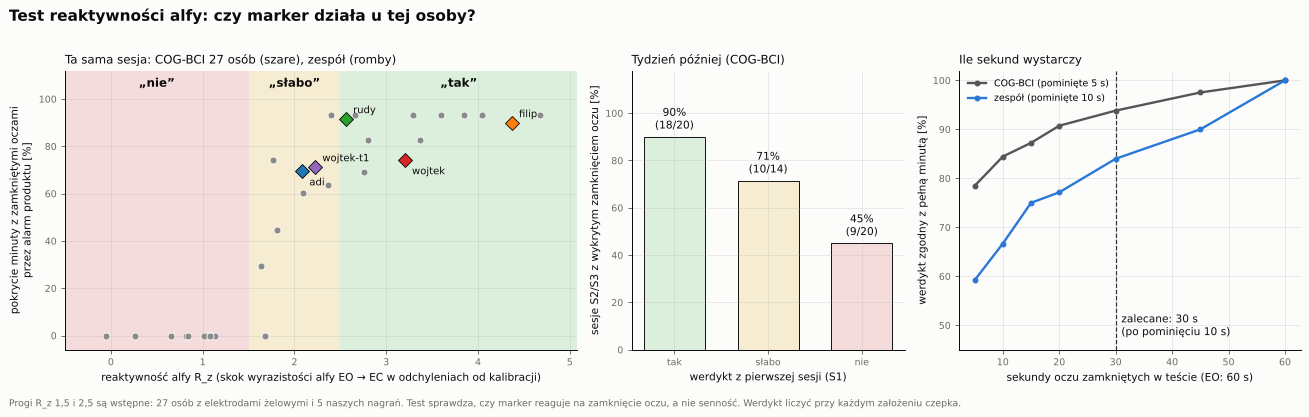

In [17]:
from matplotlib.patches import Patch

OUT = REPO / "docs" / "img" / "reaktywnosc-alfy-test-markera.png"
surface, ink, muted = "#fcfcfb", "#0b0b0b", "#6b6a66"
band = {"nie": "#f4dcdc", "słabo": "#f6ecd2", "tak": "#dcefdc"}
plt.rcParams.update({"font.family": "DejaVu Sans"})
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.8), facecolor=surface, gridspec_kw={"width_ratios": [1.5, 0.8, 1]})
ax = axes[0]
ax.set_facecolor(surface)
xmax = max(DC.R_z.max(), REL.R_z.max()) + 0.4
for lo, hi, v in ((-0.5, T_NO, "nie"), (T_NO, T_YES, "słabo"), (T_YES, xmax, "tak")):
    ax.axvspan(lo, hi, color=band[v], lw=0, zorder=0)
    ax.text((lo + hi) / 2, 104, {"nie": "„nie”", "słabo": "„słabo”", "tak": "„tak”"}[v], ha="center", va="bottom",
            fontsize=10, fontweight="bold", color=ink)
ax.scatter(DC.R_z, DC["pokrycie bloku [%]"], s=34, color="#8a8a8a", edgecolor="white", lw=0.6, zorder=2)
for n, r in REL.iterrows():
    ax.scatter(r.R_z, r["pokrycie bloku [%]"], s=70, marker="D", color=COLORS[n], edgecolor="k", lw=0.7, zorder=3)
    ax.annotate(n, (r.R_z, r["pokrycie bloku [%]"]), xytext=(6, -12 if n in ("wojtek", "adi") else 5),
                textcoords="offset points", fontsize=8.5, color=ink)
ax.set_xlim(-0.5, xmax)
ax.set_ylim(-6, 112)
ax.set_xlabel("reaktywność alfy R_z (skok wyrazistości alfy EO → EC w odchyleniach od kalibracji)", fontsize=9, color=ink)
ax.set_ylabel("pokrycie minuty z zamkniętymi oczami\nprzez alarm produktu [%]", fontsize=9, color=ink)
ax.set_title(f"Ta sama sesja: COG-BCI {len(DC)} osób (szare), zespół (romby)",
             loc="left", fontsize=10, color=ink)
ax = axes[1]
ax.set_facecolor(surface)
order = ["tak", "słabo", "nie"]
pct = [RET.loc[v, "wykryte [%]"] for v in order]
bars = ax.bar(order, pct, color=[band[v] for v in order], edgecolor=ink, lw=0.8, width=0.65)
for b_, v in zip(bars, order):
    ax.text(b_.get_x() + b_.get_width() / 2, b_.get_height() + 2,
            f"{b_.get_height():.0f}%\n({int(RET.loc[v, 'wykryte'])}/{int(RET.loc[v, 'sesji'])})", ha="center", va="bottom",
            fontsize=9, color=ink)
ax.set_ylim(0, 118)
ax.set_xlabel("werdykt z pierwszej sesji (S1)", fontsize=9, color=ink)
ax.set_ylabel("sesje S2/S3 z wykrytym zamknięciem oczu [%]", fontsize=9, color=ink)
ax.set_title("Tydzień później (COG-BCI)", loc="left", fontsize=10, color=ink)
ax = axes[2]
ax.set_facecolor(surface)
for TR, lab, col, sk in ((TR_C, "COG-BCI", "#555555", 5), (TR_T, "zespół", "#2a78d6", SKIP_EC)):
    s = TR[(TR["EO [s]"] == 60) & (TR["pominięte [s]"] == sk)]
    g = 100 * s.groupby("EC [s]")["zgodny werdykt"].mean()
    ax.plot(g.index, g.values, "-o", color=col, lw=2, ms=4, label=f"{lab} (pominięte {sk} s)")
ax.axvline(30, color=ink, lw=1, ls="--", zorder=0)
ax.text(31, 48, "zalecane: 30 s\n(po pominięciu 10 s)", ha="left", fontsize=9, color=ink)
ax.set_ylim(45, 102)
ax.set_xlabel("sekundy oczu zamkniętych w teście (EO: 60 s)", fontsize=9, color=ink)
ax.set_ylabel("werdykt zgodny z pełną minutą [%]", fontsize=9, color=ink)
ax.legend(fontsize=8, loc="upper left", frameon=False)
ax.set_title("Ile sekund wystarczy", loc="left", fontsize=10, color=ink)
for a in axes:
    a.tick_params(labelsize=8, colors=muted)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
fig.suptitle("Test reaktywności alfy: czy marker działa u tej osoby?", x=0.01, ha="left", fontsize=13,
             fontweight="bold", color=ink)
fig.text(0.01, 0.005, "Progi R_z 1,5 i 2,5 są wstępne: 27 osób z elektrodami żelowymi i 5 naszych nagrań. "
         "Test sprawdza, czy marker reaguje na zamknięcie oczu, a nie senność. Werdykt liczyć przy każdym założeniu czepka.", fontsize=8, color=muted)
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
if OUT.parent.exists():
    fig.savefig(OUT, dpi=110, facecolor=surface)
    print("zapisano docs/img/" + OUT.name, f"({OUT.stat().st_size / 1024:.0f} kB)")
plt.show()

## 7. Wnioski

**Najważniejsze:** krótki test „oczy otwarte, potem zamknięte” dobrze mówi, **czy w tej sesji** szybki wskaźnik Wachty w ogóle zobaczy
zamknięcie oczu. Miarą jest R_z, czyli skok wyrazistości alfy w odchyleniach od kalibracji. W COG-BCI (27 osób) przy R_z ≥ 2,5 detektor
produktu wykrył zamknięcie oczu u 10 z 10 osób, przy R_z < 1,5 u 0 z 10. Werdykt nie jest jednak trwałą cechą człowieka: tydzień później
ten sam werdykt miało 44–56% osób, choć po „tak” zamknięcie oczu wykryto w 90% kolejnych sesji, a po „nie” w 45%.

1. **Reaktywność zespołu (R_z, kalibracja produktu, EC od 10. s):** adi 2,09, filip 4,37, rudy 2,56, wojtek-t1 2,23, wojtek 3,20.
   To percentyle od 52 do 96 w COG-BCI (mediana populacji 1,81). Nikt z nas nie jest w grupie, u której marker nie działa.
2. **Miara:** R_z zamiast mocy alfy. Moc myli się przy rozmowie w odniesieniu (u wojtka stosunek EC/EO 0,91 względem minuty rozmowy,
   choć wyrazistość wyraźnie rośnie) i słabiej wiąże się z czułością (Spearman 0,64 wobec 0,91).
3. **Detektor na nagraniach zespołu:** produkt wykrywa 5/5 (mediana 9 s, pokrycie 79%, 1 fałszywy alarm w 48 min). Okna z zamkniętymi oczami
   w bazie psują detekcję (3/5, mediana 48 s), a próg obniżany „ułamkiem skoku” daje 20 fałszywych alarmów zamiast 1.
   **Krok kalibracji ma liczyć werdykt, ale nie zmieniać bazy ani progu.**
4. **Werdykt:** „tak” od R_z 2,5, „słabo” 1,5–2,5, „nie” poniżej 1,5. Zespół: filip, wojtek, rudy „tak”; adi i wojtek-t1 „słabo”.
   Trzy werdykty leżą blisko progu (pewność z bootstrapu 54–60%), więc są niepewne. Werdykty „słabo” mają najniższe pokrycie (69% i 71%),
   ale wszystkie pięć zamknięć oczu zostało wykrytych.
5. **Długość kroku kalibracji:** EO 60 s (istniejąca kalibracja) i EC 40 s, z czego liczymy ostatnie 30 s (93–95% zgodności z pełną minutą
   w COG-BCI). Minimum 20 s EC. Krótsze EO psuje test bardziej niż krótsze EC (EO 30 s: 78%).

**Ograniczenia:**
- **To test reakcji markera na zamknięcie oczu, a nie test senności.** Nie mówi, czy ktoś jest zmęczony, ani jak silna jest u niego alfa
  przy senności z otwartymi oczami. Założenie z §5.5, że alfa przy senności jest słabsza niż przy zamkniętych oczach, zostaje niesprawdzone.
- **Progi oparte są głównie na COG-BCI** (27 osób, elektrody żelowe, laboratorium). Zespół to 5 nagrań, 4 osoby, suche elektrody, po jednym bloku
  zamkniętych oczu na nagranie. W COG-BCI R_z i pokrycie liczymy z tej samej minuty, więc związek 0,91 jest częściowo z definicji.
  Jedyne sprawdzenie poza próbą to sesje S2 i S3.
- W zespole nikt nie dostał „nie”, więc progu dolnego na suchych elektrodach nie sprawdziliśmy.
- Odniesienie EO w nagraniach z południa to rozmowa, a nie cicha fiksacja. Zalecenie „fiksacja bez mówienia” opiera się na jednym nagraniu.
- Adnotacje bloków mogą być przesunięte o kilka sekund; stąd pominięcie 10 s.
- W COG-BCI dwie pary identycznych nagrań (`sub-17`/`sub-27`, `sub-25`/`sub-28`); duplikaty pominęliśmy.

**Co dalej:** na punktach pomiarowych T0–T2 (C1, C2) dodać 60 s fiksacji i 40 s zamkniętych oczu na początku, liczyć R_z i sprawdzić,
czy werdykt z T0 przewiduje działanie wskaźnika w nocy (C4).
